# 08 - Mixture-of-Gaussians simulation (corrected)

A controlled check of the paper's instruments on data with a known generating process. Three
well-separated Gaussian components in five dimensions, a Gaussian VAE, and two forget scenarios: the
whole of component 0 (a group), and half of component 0 (individual points of a type the model keeps
seeing). Every model is measured with the deterministic negative ELBO, one attacker trained on the
baseline and applied to every model (cross-component negatives and within-component negatives), and
the reference audit against a clean retrain with a retrain-versus-retrain floor.

The December 2025 version of this notebook scored forget points against negatives from other
components, let one method train its critic on the evaluation negatives, called gradient ascent
"Fisher", and drew every feature with an unseeded z sample; its outputs are in
`outputs/_superseded_20260908/p3__mog/` and are not citable. `src/mog.py` was rewritten with it.

In [1]:
import sys
sys.path.insert(0, '../src')
import json, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from mog import (generate_mog_data, stratified_split, forget_indices, select_matched, train_vae, retain_finetune,
                 gradient_ascent_then_finetune, forget_push, targeted_finetune, Instruments, audit_auc, audit_auc_ci, latent_mu, advantage)
from likelihood_audit import neg_elbo_per_cell

plt.style.use('seaborn-v0_8-whitegrid')
torch.set_num_threads(4)
OUTPUT_DIR = Path('../outputs/p3/mog')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
K, D, N, SEED = 3, 5, 6000, 42
VAE_KW = dict(hidden=(64, 32), latent=2, epochs=100, lr=1e-3, batch_size=256, kl_warmup_epochs=10)
X, labels, meta = generate_mog_data(K=K, d=D, n=N, seed=SEED)
train_idx, unseen_idx = stratified_split(labels, 0.2, seed=SEED)
print(f'{len(X)} points, {len(train_idx)} train, {len(unseen_idx)} held out; component sizes in training {np.bincount(labels[train_idx])}')

6000 points, 4801 train, 1199 held out; component sizes in training [1642 1578 1581]


baseline trained in 2 s


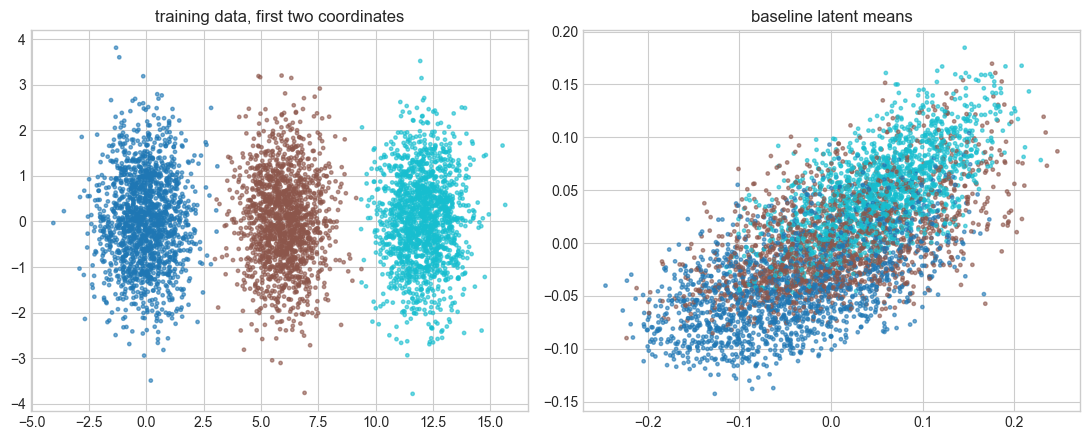

In [2]:
t0 = time.time()
baseline = train_vae(X[train_idx], seed=SEED, **VAE_KW)
print(f'baseline trained in {time.time() - t0:.0f} s')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X[train_idx, 0], X[train_idx, 1], c=labels[train_idx], cmap='tab10', s=6, alpha=0.6)
axes[0].set_title('training data, first two coordinates')
z = latent_mu(baseline, X[train_idx])
axes[1].scatter(z[:, 0], z[:, 1], c=labels[train_idx], cmap='tab10', s=6, alpha=0.6)
axes[1].set_title('baseline latent means')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'data_and_latent.png', dpi=150, bbox_inches='tight'); plt.show()

## The two scenarios

For each scenario the reference is a retrain on the retain split (seed 100), with seeds 101 and 102
giving the retrain-versus-retrain floor of the audit. The methods start from the baseline: retain-only
fine-tuning for 10 and 100 epochs, gradient ascent (50 clipped steps) then 10 retain epochs, a
continuous forget objective (the forget posteriors pushed to the prior for 20 epochs), and
likelihood-targeted fine-tuning with three targets, the retrained model's own level (an oracle), the
model's fit of the cross-component look-alikes, and its fit of the held-out points of component 0.

In [3]:
def run_scenario(fraction):
    f_idx = forget_indices(labels, train_idx, component=0, fraction=fraction, seed=SEED)
    r_idx = np.setdiff1d(train_idx, f_idx)
    pool = unseen_idx[labels[unseen_idx] != 0]
    cross = pool[select_matched(baseline, X[f_idx], X[pool], k=10)]
    within = unseen_idx[labels[unseen_idx] == 0]
    retrains = {s: train_vae(X[r_idx], seed=s, **VAE_KW) for s in (100, 101, 102)}
    ref = retrains[100]
    ins = Instruments(baseline, ref, X[f_idx], X[cross], X[within], X[r_idx], seed=SEED)
    allr = {100: ref, **retrains}
    pair_ci = {f'{a}->{b}': audit_auc_ci(allr[a], allr[b], X[f_idx], X[cross]) for a in allr for b in allr if a != b}   # every ordered pair of retrained models (reference-independent range)
    band_ci = [pair_ci['100->101'], pair_ci['100->102']]; band = [b['auc'] for b in band_ci]; band_all_pairs = [v['auc'] for v in pair_ci.values()]
    oracle = float(neg_elbo_per_cell(ref, torch.as_tensor(X[f_idx])).mean())
    models = {'baseline': baseline, 'retrain': ref,
              'retain fine-tune, 10 epochs': retain_finetune(baseline, X[r_idx], epochs=10, seed=SEED),
              'retain fine-tune, 100 epochs': retain_finetune(baseline, X[r_idx], epochs=100, seed=SEED),
              'gradient ascent + fine-tune': gradient_ascent_then_finetune(baseline, X[f_idx], X[r_idx], seed=SEED),
              'forget push (continuous)': forget_push(baseline, X[f_idx], X[r_idx], epochs=20, seed=SEED),
              'targeted, oracle level': targeted_finetune(baseline, X[f_idx], X[r_idx], target=oracle, seed=SEED)[0],
              'targeted, cross look-alikes': targeted_finetune(baseline, X[f_idx], X[r_idx], target=X[cross], seed=SEED)[0],
              'targeted, held-out same component': targeted_finetune(baseline, X[f_idx], X[r_idx], target=X[within], seed=SEED)[0]}
    rows = {name: ins.measure(m, ci=True) for name, m in models.items()}
    for s in (101, 102):
        rows[f'retrain seed {s}'] = ins.measure(retrains[s], ci=True)
    table = pd.DataFrame(rows).T
    table['advantage_cross'] = table.attacker_cross.map(advantage)
    return {'fraction': fraction, 'n_forget': len(f_idx), 'n_retain': len(r_idx), 'n_cross': len(cross), 'n_within': len(within),
            'oracle_level': oracle, 'audit_band': band, 'audit_band_ci': [b['ci95'] for b in band_ci], 'audit_band_all_pairs': band_all_pairs, 'audit_pairs': {k: v['auc'] for k, v in pair_ci.items()}, 'table': table}

t0 = time.time()
scen = {name: run_scenario(frac) for name, frac in [('whole component', 1.0), ('half of the component', 0.5)]}
print(f'both scenarios in {time.time() - t0:.0f} s')
for name, s in scen.items():
    print(f"\n{name}: forget {s['n_forget']}, retain {s['n_retain']}, cross negatives {s['n_cross']}, within negatives {s['n_within']}, "
          f"retrained level {s['oracle_level']:.2f}, audit band {[round(b, 3) for b in s['audit_band']]}")
    display(s['table'].round(3))

both scenarios in 72 s

whole component: forget 1642, retain 3159, cross negatives 689, within negatives 410, retrained level 11.94, audit band [0.46, 0.479]


,forget_neg_elbo,cross_neg_elbo,within_neg_elbo,retain_neg_elbo,attacker_cross,attacker_within,audit_cross,audit_within,audit_cross_ci,audit_within_ci,advantage_cross
baseline,8.949059,8.413846,8.912373,8.59767,0.94553,0.590369,0.999999,0.510524,"[0.9999946965451527, 1.0]","[0.47937947476307896, 0.5407186358099878]",0.891
retrain,11.937895,8.118817,11.860271,8.244537,0.995698,0.513173,0.5,0.5,"[0.5, 0.5]","[0.5, 0.5]",0.991
"retain fine-tune, 10 epochs",9.449,8.2644,9.401162,8.439367,0.969219,0.580677,0.999997,0.510015,"[0.9999893930903054, 1.0]","[0.4784697424318945, 0.5410411901013041]",0.938
"retain fine-tune, 100 epochs",11.91628,8.113765,11.839773,8.242925,0.996406,0.507547,0.570256,0.50029,"[0.5471319800095109, 0.5928319719659376]","[0.46777060247764474, 0.5317271842785418]",0.993
gradient ascent + fine-tune,9.567473,8.243573,9.517364,8.417761,0.943798,0.581157,0.999996,0.509992,"[0.9999823218171757, 1.0]","[0.4782919030925998, 0.5406689863640414]",0.888
forget push (continuous),10.265439,8.161374,10.20637,8.325702,0.742356,0.533477,0.999989,0.510889,"[0.9999575723612218, 1.0]","[0.4791210525534, 0.5418290083479397]",0.485
"targeted, oracle level",11.821481,8.363089,11.763039,8.476314,0.989718,0.492303,0.669535,0.511445,"[0.6458067792295495, 0.6919534878170802]","[0.48067381390927183, 0.5412687531564718]",0.979
"targeted, cross look-alikes",8.971252,8.41833,8.933807,8.591342,0.961475,0.584264,1.0,0.510434,"[1.0, 1.0]","[0.47943172365645703, 0.540284212441698]",0.923
"targeted, held-out same component",9.061079,8.432768,9.024218,8.586849,0.99204,0.541012,0.999995,0.511114,"[0.9999814379080346, 1.0]","[0.48089562104512634, 0.5418324433320459]",0.984
retrain seed 101,11.945413,8.112066,11.868639,8.243637,0.976111,0.493555,0.459752,0.504014,"[0.43630801537648345, 0.4828792102802168]","[0.4732556036659636, 0.5342307492350197]",0.952



half of the component: forget 821, retain 3980, cross negatives 625, within negatives 410, retrained level 9.41, audit band [0.47, 0.425]


,forget_neg_elbo,cross_neg_elbo,within_neg_elbo,retain_neg_elbo,attacker_cross,attacker_within,audit_cross,audit_within,audit_cross_ci,audit_within_ci,advantage_cross
baseline,8.974779,8.383929,8.912373,8.665005,0.948208,0.633696,0.996301,0.519101,"[0.9943029963459196, 0.9979577101096224]","[0.48542939158076115, 0.5527765069368111]",0.896
retrain,9.411664,8.273492,9.339838,8.62976,0.984019,0.50434,0.5,0.5,"[0.5, 0.5]","[0.5, 0.5]",0.968
"retain fine-tune, 10 epochs",9.241989,8.290625,9.174406,8.631801,0.97499,0.61857,0.937093,0.524411,"[0.924117466504263, 0.9490436540803897]","[0.49176316805799, 0.5586970826772824]",0.950
"retain fine-tune, 100 epochs",9.396388,8.253222,9.327945,8.626291,0.994719,0.576324,0.495362,0.520478,"[0.46457904993909865, 0.5247582216808769]","[0.48783629422774133, 0.5550748640860342]",0.989
gradient ascent + fine-tune,9.26999,8.282903,9.201881,8.630247,0.966121,0.620127,0.903801,0.522905,"[0.8873997563946407, 0.9191784165651644]","[0.4897471480348177, 0.5576233994830814]",0.932
forget push (continuous),9.351939,8.263855,9.284206,8.627536,0.860597,0.540783,0.70675,0.525195,"[0.6793837271619975, 0.733657831912302]","[0.49209938801580466, 0.5593796975728588]",0.721
"targeted, oracle level",9.366394,8.470219,9.313524,8.78073,0.999854,0.522303,0.659682,0.517712,"[0.6312074543239952, 0.6879168574908648]","[0.4839718071358546, 0.5523770832714417]",1.000
"targeted, cross look-alikes",8.989891,8.55352,8.947471,8.779813,0.99118,0.56837,0.893385,0.523328,"[0.8764743483556638, 0.9106284531059684]","[0.4890572918213957, 0.5582201212085203]",0.982
"targeted, held-out same component",9.083359,8.414708,9.029111,8.69452,0.991608,0.585633,0.879127,0.521336,"[0.8609230207064555, 0.8978959317904994]","[0.4874734856361962, 0.5546530109028251]",0.983
retrain seed 101,9.406749,8.261864,9.341523,8.627997,0.724081,0.495187,0.470099,0.5304,"[0.4399346894031669, 0.4996161510353228]","[0.49685318320905497, 0.5633674727429369]",0.448


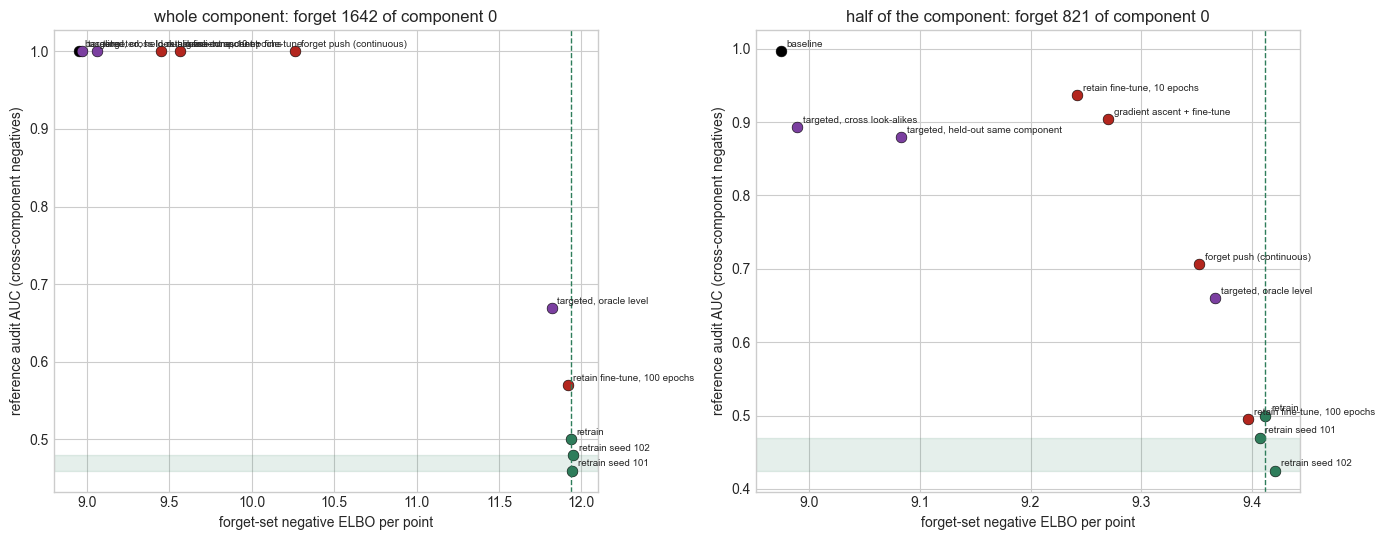

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, s) in zip(axes, scen.items()):
    t = s['table']
    for label, row in t.iterrows():
        ax.scatter(row.forget_neg_elbo, row.audit_cross, s=60, edgecolor='k', linewidth=0.4,
                   color='k' if label == 'baseline' else ('#2E7D5B' if label.startswith('retrain') else ('#7B3FA0' if label.startswith('targeted') else '#B3261E')))
        ax.annotate(label, (row.forget_neg_elbo, row.audit_cross), fontsize=7, xytext=(4, 3), textcoords='offset points')
    ax.axvline(s['oracle_level'], color='#2E7D5B', ls='--', lw=1)
    ax.axhspan(min(s['audit_band']), max(s['audit_band']), color='#2E7D5B', alpha=0.12)
    ax.set_xlabel('forget-set negative ELBO per point'); ax.set_ylabel('reference audit AUC (cross-component negatives)')
    ax.set_title(f'{name}: forget {s["n_forget"]} of component 0')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'calibration_axis.png', dpi=150, bbox_inches='tight'); plt.show()

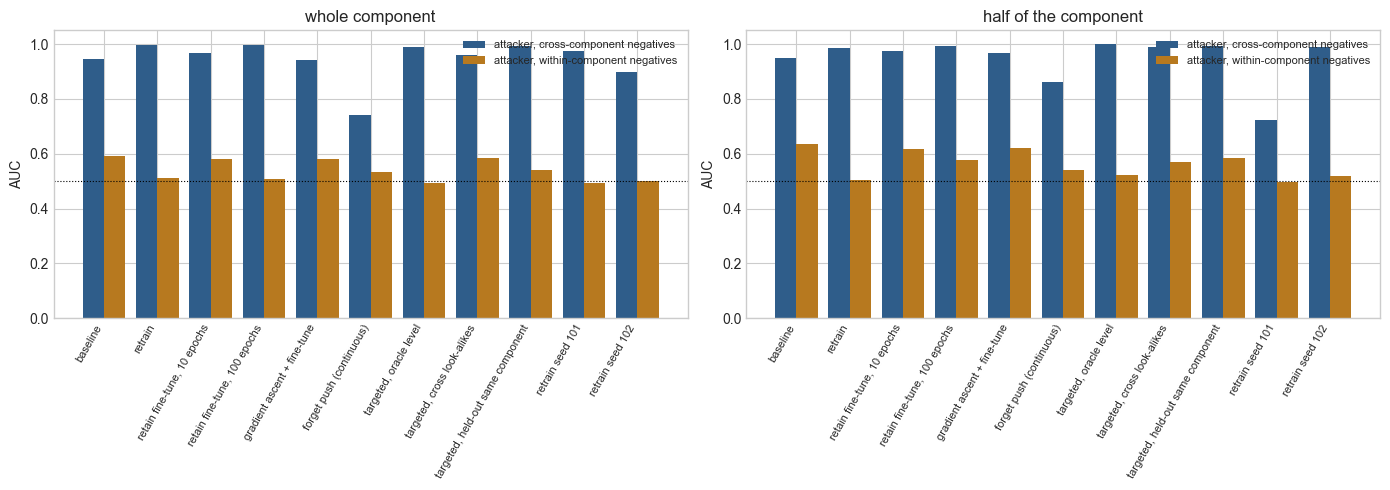

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, s) in zip(axes, scen.items()):
    t = s['table']
    xs = np.arange(len(t))
    ax.bar(xs - 0.2, t.attacker_cross, width=0.4, label='attacker, cross-component negatives', color='#2F5D8A')
    ax.bar(xs + 0.2, t.attacker_within, width=0.4, label='attacker, within-component negatives', color='#B7791F')
    ax.axhline(0.5, color='k', lw=0.8, ls=':')
    ax.set_xticks(xs); ax.set_xticklabels(t.index, rotation=60, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel('AUC'); ax.set_title(name); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'attackers.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
results = {'data': meta, 'vae': VAE_KW, 'holdout_fraction': 0.2,
           'estimator': 'likelihood_audit.neg_elbo_per_cell (eval mode, 16 seeded z samples, CPU)',
           'attacker': 'spectral-norm MLP [256, 256], dropout 0.3, 50 epochs, trained on the baseline, applied to every model',
           'scenarios': {name: {k: v for k, v in s.items() if k != 'table'} | {'table': s['table'].reset_index().rename(columns={'index': 'model'}).to_dict('records')}
                         for name, s in scen.items()},
           'superseded': 'outputs/_superseded_20260908/p3__mog/ (December 2025 run of the earlier module; not citable)'}
with open(OUTPUT_DIR / 'mog_results.json', 'w') as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(f"saved {OUTPUT_DIR / 'mog_results.json'}")

saved ../outputs/p3/mog/mog_results.json


## Summary

| Output | Path |
|---|---|
| Results | `outputs/p3/mog/mog_results.json` |
| Figures | `outputs/p3/mog/data_and_latent.png`, `calibration_axis.png`, `attackers.png` |

**Forgetting a whole component is a group effect, and the cross-component instruments read it.** The
retrained models, which never saw component 0, fit its points three nats worse than the baseline does,
so the cross-component audit reads 1.0 for the baseline and the cross-component attacker scores the
retrained models at least as high as the baseline (component 0 looks even less like the other
components to a model that never saw it). That is the Tabula Muris and TCGA-BRCA pattern from first
principles. Retain-only fine-tuning erodes the group fit to the retrained level within 100 epochs
because no retain point resembles component 0; the ten-epoch fine-tune has barely started, and
gradient ascent at the paper's mild setting adds nothing to it. The two observable targets fail in
the same direction: the model fits the cross-component look-alikes and the held-out members of
component 0 at least as well as the forget points, so neither level says "fit these worse", and only
the oracle target moves the model toward the retrained level (it stops short of the band because the
audit resolves differences smaller than the stopping tolerance).

**Per-point membership is a small latent-space signal, not a likelihood signal.** The within-component
attacker reads the baseline at 0.59 (whole component) and 0.63 (half), against 0.50 to 0.52 for the
retrained models, while the within-component audit stays at chance for every model. The training
points are placed slightly differently in the latent space, not fitted better. The 100-epoch retain
fine-tune removes that signal in the whole-component case and halves it in the half-component case.

**Forgetting half a component leaves the group in place.** With the other half in the retain set the
retrained models still know the component, and the cross-component audit's remaining signal is the
group-wide shift from having fewer component-0 training points, which the held-out members share.

The December version of this notebook concluded that "the MIA cannot distinguish" anything; the
corrected version separates the group effect from the per-point one and shows which instrument sees
which. Notebook 43 adds a rare component and the support knob.